# Sujet 04 · Allstate — Porteurs P1 et P4 (partiel)

**Question du projet** : peut-on estimer le montant d'un sinistre (`loss`) à partir de son dossier, et de combien une méthode soignée bat-elle l'estimation « sans modèle » ?

## Étapes réalisées dans ce carnet

| Porteur | Étape | Titre | Section |
|---|---|---|---|
| **P1** | 1.1 | Inventorier les tables | §1 |
| **P4** | 1.7 | Doublons | §2 |
| **P1** | 1.8 | Fuites | §3 |
| **P4** | 1.11 | La métrique | §4 |

L'ordre des sections suit la dépendance logique (on ne cherche pas de doublons avant d'avoir inventorié les tables). Dans le tableau du tableau blanc, P1 enchaîne 1.1 → 1.8 et P4 enchaîne 1.7 → 1.11 → 1.12 ; **ici on fait toutes les étapes de P1 (1.1, 1.8) et les deux premières de P4 (1.7, 1.11)**.

**Comment lire ce carnet** : chaque cellule de code est précédée de *ce qu'on cherche* et suivie de *comment lire le résultat*. Chaque section se termine par un encadré **Conclusion** à recopier dans votre journal.

### Mode d'emploi sur Kaggle
1. Créez un jeu de données privé contenant `train.csv` et `a_estimer.csv` (kaggle.com/datasets → New Dataset).
2. Importez ce carnet (File → Import Notebook), puis **Add Input** → votre jeu de données.
3. *Session options* → Accelerator : **None**, Internet : **désactivé**.
4. **Run All**, puis **Save Version → Save & Run All (Commit)** pour conserver les sorties.

Aucun modèle n'est entraîné ici : le carnet s'exécute en moins d'une minute.

In [1]:
# --- 0. Réglages et localisation des fichiers (rien n'est codé en dur) -------
import os, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
CIBLE, ID = "loss", "id"
FICHIERS = ["train.csv", "a_estimer.csv"]
RESULTATS = {}          # on y range les chiffres clés ; ils seront sauvegardés à la fin

def trouver_donnees():
    pistes = []
    if os.environ.get("DONNEES_PROJET"): pistes.append(Path(os.environ["DONNEES_PROJET"]))
    ici = Path.cwd().resolve()
    pistes += [ici, ici / "donnees", ici / "Sujet_04_Allstate"] + list(ici.parents)[:3]
    kg = Path("/kaggle/input")
    if kg.exists():
        pistes += [kg] + [d for d in kg.rglob("*") if d.is_dir()][:200]
    for p in pistes:
        if p.exists() and all((p / f).is_file() for f in FICHIERS):
            return p
    raise FileNotFoundError("Dossier introuvable : il faut train.csv et a_estimer.csv. "
                            "Sur Kaggle : Add Input -> votre jeu de donnees.")

DOSSIER = trouver_donnees()
print("dossier de données :", DOSSIER)

dossier de données : /kaggle/input/datasets/ahehehinnoupeniel/allstate-sujet4


In [2]:
# ============================ FICHE PORTEUR (à remplir) ============================
# Recopiez ici ce qui est écrit sur le tableau blanc : Séance / Nom / Porteur # / Étapes assignées
SEANCE           = "Séance 1"                      # <- numéro ou date de la séance
NOM              = "Peniel"                        # <- votre nom
GROUPE           = 3
Sujet            = 4
PORTEUR          = "P1 + P4"                       # <- votre numéro de porteur (P1, P2, P3, P4 ou une combinaison)
ETAPES_ASSIGNEES = ["1.1", "1.8", "1.7", "1.11"]   # <- les étapes qui vous sont assignées
# ====================================================================================

on_kaggle = Path("/kaggle/working").exists()       # True quand le carnet tourne sur Kaggle
BASE      = "/kaggle/working" if on_kaggle else "."
DATE      = pd.Timestamp.today().strftime("%d/%m/%Y")

# Étapes couvertes par CE carnet (d'après le tableau blanc : P1 = 1.1 puis 1.8 ; P4 = 1.7 puis 1.11)
ETAPES = {"1.1": ("P1", "Inventorier les tables"), "1.7": ("P4", "Doublons"),
          "1.8": ("P1", "Fuites"),                 "1.11": ("P4", "La métrique")}

def qui(etape):
    """Affiche, au début d'une section, si l'étape est assignée à la personne de la fiche."""
    p, titre = ETAPES[etape]
    statut = f"assignée à {NOM}" if etape in ETAPES_ASSIGNEES else "NON assignée à cette fiche"
    print(f"▶ Étape {etape} — {titre} | porteur {p} | {statut}")

print("=" * 60)
print(f" Séance            : {SEANCE}")
print(f" Nom               : {NOM}")
print(f" Porteur #         : {PORTEUR}")
print(f" Étapes assignées  : {', '.join(ETAPES_ASSIGNEES)}")
print(f" Date d'exécution  : {DATE}")
print("=" * 60)

inconnues = [e for e in ETAPES_ASSIGNEES if e not in ETAPES]
if inconnues:
    print("⚠ étapes assignées qui ne sont PAS traitées dans ce carnet :", inconnues)
display(pd.DataFrame([dict(étape=e, titre=t, porteur_prévu=p, statut="✔ assignée à " + NOM if e in ETAPES_ASSIGNEES else "—")
                      for e, (p, t) in sorted(ETAPES.items(), key=lambda kv: tuple(map(int, kv[0].split("."))))]))

 Séance            : Séance 1
 Nom               : Peniel
 Porteur #         : P1 + P4
 Étapes assignées  : 1.1, 1.8, 1.7, 1.11
 Date d'exécution  : 09/11/2026


,étape,titre,porteur_prévu,statut
0,1.1,Inventorier les tables,P1,✔ assignée à Peniel
1,1.7,Doublons,P4,✔ assignée à Peniel
2,1.8,Fuites,P1,✔ assignée à Peniel
3,1.11,La métrique,P4,✔ assignée à Peniel


---
# §1 · Étape 1.1 — Inventorier les tables *(P1)*

**Ce qu'on cherche.** Avant toute analyse, on vérifie que ce qu'on a reçu est **bien ce que l'énoncé annonce** : combien de fichiers, combien de lignes, combien de colonnes, quel poids, quelles colonnes en commun. C'est le contrôle « le dossier n'est pas tronqué ».

**Ce que dit l'énoncé (valeurs attendues).**
- `train.csv` : 150 654 lignes × 132 colonnes (dont `loss`)
- `a_estimer.csv` : 37 664 lignes × 131 colonnes (sans `loss`)
- poids total du dossier attendu : 70,3 Mo

In [3]:
qui("1.1")

▶ Étape 1.1 — Inventorier les tables | porteur P1 | assignée à Peniel


In [4]:
# --- 1.1 Inventaire : fichiers, poids, dimensions ----------------------------
tr = pd.read_csv(DOSSIER / "train.csv")
te = pd.read_csv(DOSSIER / "a_estimer.csv")
TABLES = {"train.csv": tr, "a_estimer.csv": te}
ATTENDU = {"train.csv": (150_654, 132), "a_estimer.csv": (37_664, 131)}

lignes = []
for nom, t in TABLES.items():
    poids = (DOSSIER / nom).stat().st_size / 1e6
    lignes.append(dict(fichier=nom, poids_Mo=round(poids, 1), lignes=t.shape[0], colonnes=t.shape[1],
                       attendu=ATTENDU[nom], conforme=(t.shape == ATTENDU[nom]),
                       memoire_Mo=round(t.memory_usage(deep=True).sum() / 1e6, 1)))
inventaire = pd.DataFrame(lignes)
display(inventaire)
print("poids total des CSV :", round(inventaire.poids_Mo.sum(), 1), "Mo (l'énoncé annonce 70,3 Mo pour le dossier complet)")

,fichier,poids_Mo,lignes,colonnes,attendu,conforme,memoire_Mo
0,train.csv,56.5,150654,132,"(150654, 132)",True,893.7
1,a_estimer.csv,13.8,37664,131,"(37664, 131)",True,223.1


poids total des CSV : 70.3 Mo (l'énoncé annonce 70,3 Mo pour le dossier complet)


**Comment lire.** La colonne `conforme` doit valoir `True` partout : sinon un fichier est tronqué ou ce n'est pas la bonne version. `memoire_Mo` est le poids **une fois chargé** : il est bien supérieur au poids du CSV, surtout à cause des 116 colonnes de texte (type texte). C'est la raison pour laquelle on convertira plus tard les catégorielles en entiers ou en type `category`.

In [5]:
# --- 1.1 Colonnes : communes, propres à chaque table -------------------------
cols_tr, cols_te = set(tr.columns), set(te.columns)
print("colonnes seulement dans train  :", sorted(cols_tr - cols_te))
print("colonnes seulement dans a_estimer :", sorted(cols_te - cols_tr))
print("colonnes communes :", len(cols_tr & cols_te))

familles = {"id": [ID],
            "catégorielles (cat*)": [c for c in tr if c.startswith("cat")],
            "continues (cont*)":    [c for c in tr if c.startswith("cont")],
            "cible": [CIBLE]}
print()
for nom, cs in familles.items():
    print(f"{nom:24s} : {len(cs):4d} colonnes")
# l'ordre des colonnes communes est-il identique ? (important pour ne pas décaler X entre train et test)
communes = [c for c in tr.columns if c in cols_te]
print("\nordre des colonnes identique train / a_estimer :", communes == list(te.columns))

colonnes seulement dans train  : ['loss']
colonnes seulement dans a_estimer : []
colonnes communes : 131

id                       :    1 colonnes
catégorielles (cat*)     :  116 colonnes
continues (cont*)        :   14 colonnes
cible                    :    1 colonnes

ordre des colonnes identique train / a_estimer : True


**Comment lire.** On attend : **une seule colonne** propre à `train` (`loss`, la cible) et **aucune** propre à `a_estimer`. Cela signifie que `a_estimer` a exactement les mêmes variables explicatives : un modèle appris sur `train` sera directement applicable. On compte aussi 1 `id` + 116 `cat` + 14 `cont` + 1 `loss` = 132. L'ordre identique des colonnes évite une erreur classique : appliquer un modèle à des colonnes décalées.

In [6]:
# --- 1.1 Aperçu des types réels ----------------------------------------------
types = tr.dtypes.astype(str).value_counts().rename("nb_colonnes").to_frame()
display(types)
display(tr.iloc[:5, :6].join(tr[["cont1", "cont2", CIBLE]]))
RESULTATS["1.1_inventaire"] = {n: dict(lignes=int(t.shape[0]), colonnes=int(t.shape[1])) for n, t in TABLES.items()}

,nb_colonnes
object,116
float64,16


,id,cat1,cat2,cat3,cat4,cat5,cont1,cont2,loss
0,585230.0,B,A,A,B,A,0.315300,0.199504,1152.15
1,431675.0,B,A,A,A,A,0.472892,0.422197,2767.09
2,498682.0,A,B,A,A,A,0.702649,0.620805,1665.79
3,456113.0,B,A,A,A,B,0.461344,0.737068,1802.72
4,587001.0,A,B,A,B,A,0.513457,0.737068,5731.76


**Comment lire.** `str` (ou `object` selon la version de pandas) = texte (les 116 `cat*`) ; `float64` = décimaux : les 14 `cont*`, `loss`, et aussi `id`, qui est stocké comme un décimal dans le fichier (584230.0). **Attention** : `id` est un simple numéro interne (à convertir en entier à l'écriture de la soumission), ce n'est pas une variable explicative (on le retire des variables avant modélisation, voir §3).

> **Conclusion 1.1 (à recopier dans le journal)** : 2 tables, dimensions conformes à l'énoncé, 130 variables explicatives communes (116 catégorielles + 14 continues), `loss` seule colonne absente de `a_estimer`. Le dossier est complet.

---
# §2 · Étape 1.7 — Doublons *(P4)*

**Ce qu'on cherche.** Trois types de doublons, qui n'ont pas la même gravité :

1. **Identifiants en double** : deux lignes avec le même `id` → erreur de collecte.
2. **Lignes entièrement identiques** (toutes les variables, hors `id`) : un même dossier compté plusieurs fois → il pèse deux fois dans l'entraînement, et, pire, il peut se retrouver à la fois dans l'entraînement et la validation (cela gonfle le score).
3. **Mêmes variables mais cibles différentes** : deux dossiers identiques dont le `loss` diffère. Cela mesure le **bruit irréductible** : aucun modèle ne peut faire mieux que ce bruit.

In [7]:
qui("1.7")

▶ Étape 1.7 — Doublons | porteur P4 | assignée à Peniel


In [8]:
# --- 1.7 Doublons d'identifiant ----------------------------------------------
for nom, t in TABLES.items():
    print(f"{nom:15s} id dupliqués : {t[ID].duplicated().sum()}  |  id manquants : {t[ID].isna().sum()}")
print("id communs train / a_estimer :", len(set(tr[ID]) & set(te[ID])))

train.csv       id dupliqués : 0  |  id manquants : 0
a_estimer.csv   id dupliqués : 0  |  id manquants : 0
id communs train / a_estimer : 0


**Comment lire.** On attend **0** partout. Si `id communs` était > 0, un même sinistre serait à la fois à apprendre et à estimer.

In [9]:
# --- 1.7 Doublons de contenu (toutes les variables, hors id et hors cible) ---
X_cols = [c for c in tr.columns if c not in (ID, CIBLE)]
dup_tr = tr.duplicated(subset=X_cols, keep=False)
dup_te = te.duplicated(subset=X_cols, keep=False)
print("lignes de train dont les 130 variables sont identiques à une autre ligne de train :", int(dup_tr.sum()))
print("idem dans a_estimer :", int(dup_te.sum()))

# Même contenu entre train et a_estimer ? (une seule jointure, sur les 130 variables)
cles_tr = pd.util.hash_pandas_object(tr[X_cols], index=False)
cles_te = pd.util.hash_pandas_object(te[X_cols], index=False)
commun = int(cles_te.isin(set(cles_tr)).sum())
print("lignes de a_estimer ayant un jumeau exact dans train :", commun)

lignes de train dont les 130 variables sont identiques à une autre ligne de train : 2
idem dans a_estimer : 0
lignes de a_estimer ayant un jumeau exact dans train : 0


**Comment lire.** Si ces nombres sont **0 ou quasi 0**, il n'y a pas de dossier recopié : pas de risque que la validation « triche » en retrouvant un jumeau dans l'entraînement. S'ils étaient élevés, il faudrait découper la validation **par groupes** de dossiers identiques (`GroupKFold`) plutôt qu'au hasard.

In [10]:
# --- 1.7 Bruit irréductible : mêmes variables, cibles différentes ------------
if dup_tr.any():
    g = tr[dup_tr].groupby(X_cols)[CIBLE].agg(["count", "min", "max"])
    g["ecart"] = g["max"] - g["min"]
    print("groupes de jumeaux :", len(g), "| écart moyen de loss au sein d'un groupe :", round(g["ecart"].mean(), 1))
    display(g.sort_values("ecart", ascending=False).reset_index(drop=True).head())
else:
    print("Aucun groupe de lignes jumelles : l'analyse du bruit par jumeaux n'est pas applicable.")
RESULTATS["1.7_doublons"] = dict(id_dupliques_train=int(tr[ID].duplicated().sum()),
    id_dupliques_test=int(te[ID].duplicated().sum()), id_communs=len(set(tr[ID]) & set(te[ID])),
    lignes_jumelles_train=int(dup_tr.sum()), lignes_jumelles_test=int(dup_te.sum()), jumeaux_train_test=commun)

groupes de jumeaux : 1 | écart moyen de loss au sein d'un groupe : 148.1


,count,min,max,ecart
0,2,637.98,786.07,148.09


**Comment lire.** Chaque groupe regroupe des dossiers identiques ; `ecart` est la différence entre le plus petit et le plus grand `loss` du groupe. Un écart élevé prouve que même deux dossiers identiques ont des montants différents : l'erreur d'un modèle ne pourra jamais être nulle.

> **Conclusion 1.7 (journal)** — résultats sur les données livrées : 0 `id` dupliqué, 0 `id` commun entre les deux tables, **2 lignes jumelles dans `train`** (1 seul groupe, écart de `loss` de ≈148 entre elles), 0 dans `a_estimer`, 0 jumeau train/test. Décision : ces 2 lignes sont négligeables (0,001 % de `train`) ; on les garde, on n'a pas besoin de `GroupKFold`, et on le note dans le journal. Leur écart de 148 confirme qu'il existe un bruit irréductible, mais il est faible ici.

---
# §3 · Étape 1.8 — Fuites *(P1)*

**Règle du cours** : *« Une information qui ne serait pas connue au moment où le dossier est instruit ne peut pas entrer dans le modèle. »*

Une **fuite** (leakage) est une information qui laisse le modèle « voir » la réponse pendant l'entraînement ou la validation, sans être disponible en situation réelle. Un modèle avec fuite a un **excellent score de validation et un mauvais score réel**. Quatre contrôles :

1. la cible est-elle présente dans `a_estimer` ? (elle ne doit pas l'être)
2. l'`id` est-il lié à la cible ? (ordre d'arrivée, date cachée…)
3. une variable est-elle **trop** corrélée à la cible ? (suspect : variable calculée à partir du montant)
4. `train` et `a_estimer` ont-ils la même distribution ? (sinon la validation ne représente pas le test)

In [11]:
qui("1.8")

▶ Étape 1.8 — Fuites | porteur P1 | assignée à Peniel


In [12]:
# --- 1.8 (1) Cible dans a_estimer ? ------------------------------------------
print("`loss` présente dans a_estimer :", CIBLE in te.columns)
suspects = [c for c in te.columns if "loss" in c.lower() or "target" in c.lower() or "cible" in c.lower()]
print("colonnes au nom suspect dans a_estimer :", suspects)

`loss` présente dans a_estimer : False
colonnes au nom suspect dans a_estimer : []


**Comment lire.** On attend `False` et une liste vide.

In [13]:
# --- 1.8 (2) L'identifiant porte-t-il de l'information sur la cible ? --------
rho_id, p_id = stats.spearmanr(tr[ID], tr[CIBLE])
print(f"corrélation de Spearman id ~ loss : {rho_id:+.4f} (p = {p_id:.2g})")

tr_tri = tr.sort_values(ID).reset_index(drop=True)
tr_tri["tranche_id"] = pd.qcut(tr_tri.index, 10, labels=False)
par_tranche = tr_tri.groupby("tranche_id")[CIBLE].agg(mediane="median", moyenne="mean")
display(par_tranche.round(0).T)

print("\nplage des id  train :", tr[ID].min(), "→", tr[ID].max())
print("plage des id  a_estimer :", te[ID].min(), "→", te[ID].max())
melange = (te[ID].min() < tr[ID].max()) and (tr[ID].min() < te[ID].max())
print("les deux plages se chevauchent (découpe aléatoire) :", melange)

corrélation de Spearman id ~ loss : -0.0033 (p = 0.2)


tranche_id,0,1,2,3,4,5,6,7,8,9
mediane,2114.0,2124.0,2128.0,2114.0,2145.0,2112.0,2112.0,2109.0,2113.0,2087.0
moyenne,3057.0,3021.0,3060.0,3030.0,3053.0,3042.0,3065.0,3035.0,3010.0,3016.0



plage des id  train : 1.0 → 587633.0
plage des id  a_estimer : 5.0 → 587630.0
les deux plages se chevauchent (découpe aléatoire) : True


**Comment lire.**
- Une corrélation `id ~ loss` proche de **0** (|ρ| < 0,05) = l'`id` ne contient pas de tendance exploitable. Si elle était forte, `id` cacherait une date ou un ordre d'arrivée : il faudrait alors une validation **temporelle**, et il ne faudrait **pas** l'utiliser comme variable.
- La médiane de `loss` par dixième d'`id` doit rester à peu près **plate**.
- Si les plages d'`id` se chevauchent, `a_estimer` a été tiré **au hasard** dans la même population que `train` : un découpage aléatoire (KFold) est donc honnête.
- **Dans tous les cas, on retire `id` des variables du modèle.**

In [14]:
# --- 1.8 (3) Une variable continue est-elle trop liée à la cible ? -----------
cont = [c for c in tr if c.startswith("cont")]
corr = pd.DataFrame({
    "pearson":  [tr[c].corr(tr[CIBLE]) for c in cont],
    "spearman": [stats.spearmanr(tr[c], tr[CIBLE])[0] for c in cont]}, index=cont)
corr["|max|"] = corr.abs().max(axis=1)
display(corr.sort_values("|max|", ascending=False).round(3))
print("corrélation absolue maximale :", round(corr["|max|"].max(), 3), "→", "SUSPECT (> 0,9)" if corr["|max|"].max() > 0.9 else "aucune fuite évidente")

,pearson,spearman,|max|
cont2,0.141,0.080,0.141
cont7,0.125,0.058,0.125
cont3,0.110,0.069,0.110
cont11,0.104,0.057,0.104
cont12,0.103,0.056,0.103
cont6,0.045,0.022,0.045
cont4,-0.037,-0.030,0.037
cont8,0.031,0.027,0.031
cont10,0.023,0.005,0.023
cont14,0.019,0.000,0.019


corrélation absolue maximale : 0.141 → aucune fuite évidente


**Comment lire.** Une variable continue dont la corrélation avec le montant dépasse ~0,9 est **suspecte** : elle a probablement été calculée à partir de la cible (ex. un montant déjà payé). Ici, des corrélations faibles à modérées sont normales : le signal est **diffus**, réparti sur beaucoup de variables, ce qui explique qu'un modèle non linéaire (arbres) fera mieux qu'une régression linéaire.

*Note* : on a testé les continues. Pour les 116 catégorielles, une fuite se verrait par une modalité « pure » (toujours le même montant) ; ce sera à vérifier lors de l'encodage cible, **à l'intérieur de chaque pli de validation** (calcul sur le pli d'entraînement seulement), faute de quoi on crée soi-même une fuite.

In [15]:
# --- 1.8 (4) Train et a_estimer ont-ils la même distribution ? ---------------
ks = pd.DataFrame({c: dict(zip(["KS", "p"], stats.ks_2samp(tr[c], te[c]))) for c in cont}).T
ks["alerte"] = ks["KS"] > 0.02
display(ks.round(4))
print("variables avec décalage notable (KS > 0,02) :", int(ks["alerte"].sum()), "sur", len(cont))

cat = [c for c in tr if c.startswith("cat")]
inconnues = {c: int((~te[c].isin(tr[c].unique())).sum()) for c in cat}
inconnues = {c: n for c, n in inconnues.items() if n}
print("\nmodalités de a_estimer jamais vues dans train :", inconnues if inconnues else "aucune")
RESULTATS["1.8_fuites"] = dict(spearman_id_loss=round(float(rho_id), 4),
    corr_max_cont=round(float(corr["|max|"].max()), 3), ks_max=round(float(ks["KS"].max()), 4),
    modalites_inconnues=inconnues, plages_id_chevauchent=bool(melange))

,KS,p,alerte
cont1,0.0051,0.4196,False
cont2,0.0025,0.9916,False
cont3,0.0028,0.9724,False
cont4,0.0090,0.0146,False
cont5,0.0043,0.6347,False
cont6,0.0046,0.5372,False
cont7,0.0050,0.4417,False
cont8,0.0093,0.0107,False
cont9,0.0036,0.8271,False
cont10,0.0044,0.5972,False


variables avec décalage notable (KS > 0,02) : 0 sur 14

modalités de a_estimer jamais vues dans train : {'cat89': 1, 'cat101': 1, 'cat109': 4, 'cat110': 1, 'cat116': 10}


**Comment lire.**
- La statistique **KS** (Kolmogorov–Smirnov) mesure l'écart maximal entre les deux distributions : 0 = identiques, 1 = totalement différentes. Une valeur < 0,02 indique que `a_estimer` ressemble à `train`, donc que le score de validation sera représentatif.
- **Modalités jamais vues** : quelques catégorielles (en général de rares modalités) apparaissent dans `a_estimer` sans exister dans `train`. Le pipeline doit donc **gérer l'inconnu** (par ex. `OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)`), sinon il plante à la prédiction.

> **Conclusion 1.8 (journal)** : cible absente de `a_estimer` ; `id` sans lien avec `loss` et à exclure des variables ; aucune continue suspecte ; distributions train/test comparables ; modalités inconnues à gérer dans l'encodage ; encodage cible uniquement *dans* les plis.

---
# §4 · Étape 1.11 — La métrique *(P4)*

**Ce qu'on décide.** Une métrique n'est pas qu'un score : elle **définit ce qu'est une bonne réponse**. Le carnet de départ impose l'**erreur absolue** (MAE, *Mean Absolute Error*) :

$$\text{MAE} = \frac{1}{n}\sum_i |y_i - \hat y_i|$$

**Conséquences à démontrer** (et pas seulement à affirmer) :

1. la valeur unique qui minimise la MAE est la **médiane**, pas la moyenne ;
2. une erreur de 100 € coûte toujours 100 €, qu'elle porte sur un petit ou un gros sinistre (contrairement à la RMSE qui punit les gros écarts au carré) ;
3. le score d'un modèle se lit **par rapport à une constante de référence mesurée**, pas par rapport à zéro.

In [16]:
qui("1.11")

▶ Étape 1.11 — La métrique | porteur P4 | assignée à Peniel


min             0.7
p1            391.4
p5            618.1
p25          1204.8
médiane      2115.6
p75          3865.6
p95          8519.7
p99         14025.8
max        121012.2

moyenne = 3038.9 | médiane = 2115.6 | asymétrie (skewness) = 3.93


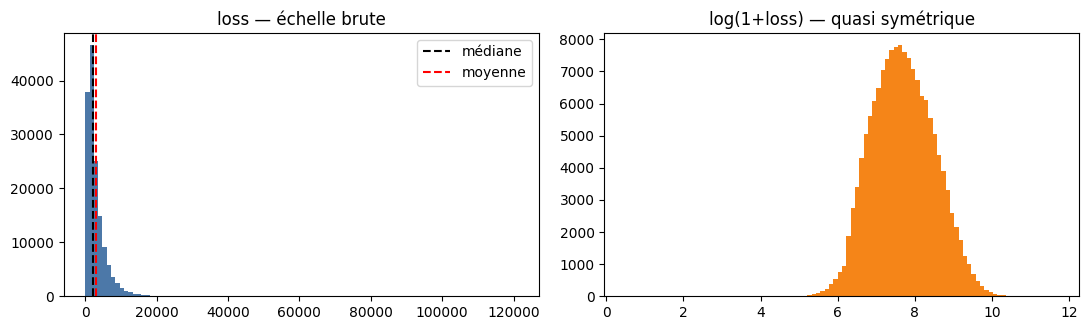

In [17]:
# --- 1.11 (a) Forme de la cible : pourquoi médiane ≠ moyenne ? ----------------
y = tr[CIBLE].to_numpy()
q = np.percentile(y, [0, 1, 5, 25, 50, 75, 95, 99, 100])
print(pd.Series(q, index=["min", "p1", "p5", "p25", "médiane", "p75", "p95", "p99", "max"]).round(1).to_string())
print(f"\nmoyenne = {y.mean():.1f} | médiane = {np.median(y):.1f} | asymétrie (skewness) = {stats.skew(y):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(y, bins=100, color="#4C78A8"); ax[0].axvline(np.median(y), c="k", ls="--", label="médiane"); ax[0].axvline(y.mean(), c="r", ls="--", label="moyenne")
ax[0].set_title("loss — échelle brute"); ax[0].legend()
ax[1].hist(np.log1p(y), bins=100, color="#F58518"); ax[1].set_title("log(1+loss) — quasi symétrique")
plt.tight_layout(); plt.show()

**Comment lire.** La cible est **très asymétrique à droite** : beaucoup de petits montants, quelques énormes (jusqu'à ~121 000). La moyenne est tirée vers le haut par ces rares gros sinistres, donc **moyenne > médiane**. Sur l'échelle logarithmique (graphique de droite), la distribution devient presque symétrique : c'est un indice qu'on pourra modéliser `log(1+loss)`. Avec la MAE, on peut faire cela sans biais, car **la médiane est conservée par une transformation monotone** (la médiane de log(y) est le log de la médiane de y).

,constante,MAE,RMSE
zéro,0.0,3038.9,4211.0
moyenne,3038.9,1968.1,2915.0
médiane,2115.6,1810.5,3057.7


constante minimisant la MAE sur la grille : 2115  (médiane = 2116)


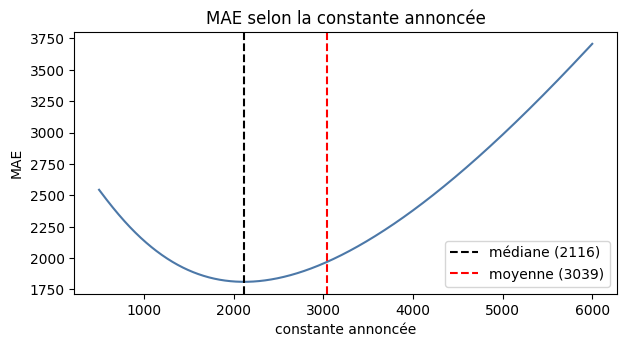

In [18]:
# --- 1.11 (b) La constante de référence, MESURÉE -----------------------------
def mae(y, p):  return float(np.mean(np.abs(y - p)))
def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))

candidats = {"zéro": 0.0, "moyenne": float(y.mean()), "médiane": float(np.median(y))}
tableau = pd.DataFrame({nom: dict(constante=round(c, 1), MAE=round(mae(y, c), 1), RMSE=round(rmse(y, c), 1))
                        for nom, c in candidats.items()}).T
display(tableau)

# Preuve numérique : on balaye toutes les constantes possibles et on regarde où la MAE est minimale
grille = np.linspace(500, 6000, 1101)
mae_grille = np.array([np.mean(np.abs(y - c)) for c in grille])
c_opt = grille[mae_grille.argmin()]
print(f"constante minimisant la MAE sur la grille : {c_opt:.0f}  (médiane = {np.median(y):.0f})")

plt.figure(figsize=(7, 3.4))
plt.plot(grille, mae_grille, c="#4C78A8")
plt.axvline(np.median(y), c="k", ls="--", label=f"médiane ({np.median(y):.0f})")
plt.axvline(y.mean(), c="r", ls="--", label=f"moyenne ({y.mean():.0f})")
plt.xlabel("constante annoncée"); plt.ylabel("MAE"); plt.title("MAE selon la constante annoncée"); plt.legend(); plt.show()

**Comment lire.**
- **Zéro** : MAE = moyenne de `loss` (puisque tout est positif). C'est le « score nul » à ne **pas** prendre comme référence : annoncer 0 € n'est pas ce que fait un assureur.
- **Moyenne** : meilleure que zéro, mais **pas optimale** pour la MAE.
- **Médiane** : la MAE la plus basse. La courbe le montre : elle atteint son minimum **à la médiane**, pas à la moyenne. C'est **la constante de référence** (la réponse à « si l'on n'a aucun modèle, quelle valeur unique annoncer ? »).
- La RMSE de la médiane est plus mauvaise que celle de la moyenne : chaque métrique a sa propre « meilleure constante ». **C'est pourquoi une mauvaise métrique donne de mauvaises décisions.**

In [19]:
# --- 1.11 (c) Ce que la métrique implique : l'erreur ne grossit pas au carré --
M = float(np.median(y))
gros = y > np.percentile(y, 99)
print(f"part des 1 % plus gros sinistres dans la MAE de la médiane  : {np.abs(y[gros]-M).sum() / np.abs(y-M).sum():.1%}")
print(f"part des 1 % plus gros sinistres dans le MSE de la médiane  : {((y[gros]-M)**2).sum() / ((y-M)**2).sum():.1%}")

part des 1 % plus gros sinistres dans la MAE de la médiane  : 9.1%
part des 1 % plus gros sinistres dans le MSE de la médiane  : 33.5%


**Comment lire.** Avec la MAE, les 1 % de plus gros sinistres pèsent **environ 9 %** du score ; avec une erreur quadratique, ils en pèseraient **environ un tiers** (33 %) à eux seuls. Choisir la MAE revient à dire : « je veux être bon **sur le sinistre typique**, sans que quelques énormes sinistres dictent le modèle ». C'est cohérent avec une provision par dossier à budgéter en moyenne, moins avec la tarification des queues de risque (à discuter dans la note).

In [20]:
# --- 1.11 (d) Comment on lira le score d'un modèle ---------------------------
MAE_REF = mae(y, np.median(y))
print(f"MAE de référence (médiane) = {MAE_REF:.1f}")
print("Gain d'un modèle = 1 - MAE_modèle / MAE_référence")
for exemple in (1700, 1400, 1151):
    print(f"   MAE modèle = {exemple}  →  gain = {1 - exemple / MAE_REF:.1%}")
RESULTATS["1.11_metrique"] = dict(metrique="MAE", constante_reference="mediane", mediane=round(M, 2),
    moyenne=round(float(y.mean()), 2), MAE_reference=round(MAE_REF, 1), MAE_si_moyenne=round(mae(y, y.mean()), 1),
    MAE_si_zero=round(mae(y, 0.0), 1), skewness=round(float(stats.skew(y)), 2))

MAE de référence (médiane) = 1810.5
Gain d'un modèle = 1 - MAE_modèle / MAE_référence
   MAE modèle = 1700  →  gain = 6.1%
   MAE modèle = 1400  →  gain = 22.7%
   MAE modèle = 1151  →  gain = 36.4%


**Comment lire.** `MAE_reference` est **le chiffre à battre** : tout modèle sera présenté comme *« X % mieux que la médiane »*. Les trois exemples ne sont que des illustrations du calcul du gain.

> **Conclusion 1.11 (journal)** : métrique = **MAE**. Constante de référence = **médiane de `loss`** (valeur affichée ci-dessus), pas la moyenne ni zéro. Score d'un modèle = gain relatif sur la MAE de la médiane. La cible étant asymétrique, on peut modéliser `log(1+loss)` avec une perte absolue sans fausser la métrique.

---
# Bilan et sauvegarde

On range tous les chiffres dans un fichier JSON : ils alimenteront le journal des essais, la note de 3 pages, la model card et la fiche de données.

In [21]:
sortie = Path(BASE)
RESULTATS["fiche_porteur"] = dict(seance=SEANCE, nom=NOM, porteur=PORTEUR, etapes_assignees=ETAPES_ASSIGNEES, date=DATE)
(sortie / "resultats_P1_P4.json").write_text(json.dumps(RESULTATS, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("écrit :", sortie / "resultats_P1_P4.json")
print(json.dumps(RESULTATS, indent=2, ensure_ascii=False, default=str))

écrit : /kaggle/working/resultats_P1_P4.json
{
  "1.1_inventaire": {
    "train.csv": {
      "lignes": 150654,
      "colonnes": 132
    },
    "a_estimer.csv": {
      "lignes": 37664,
      "colonnes": 131
    }
  },
  "1.7_doublons": {
    "id_dupliques_train": 0,
    "id_dupliques_test": 0,
    "id_communs": 0,
    "lignes_jumelles_train": 2,
    "lignes_jumelles_test": 0,
    "jumeaux_train_test": 0
  },
  "1.8_fuites": {
    "spearman_id_loss": -0.0033,
    "corr_max_cont": 0.141,
    "ks_max": 0.0093,
    "modalites_inconnues": {
      "cat89": 1,
      "cat101": 1,
      "cat109": 4,
      "cat110": 1,
      "cat116": 10
    },
    "plages_id_chevauchent": true
  },
  "1.11_metrique": {
    "metrique": "MAE",
    "constante_reference": "mediane",
    "mediane": 2115.57,
    "moyenne": 3038.92,
    "MAE_reference": 1810.5,
    "MAE_si_moyenne": 1968.1,
    "MAE_si_zero": 3038.9,
    "skewness": 3.93
  },
  "fiche_porteur": {
    "seance": "Séance 1",
    "nom": "Peniel",
    "p

### Ce qu'il reste à faire (autres porteurs)
Les étapes 1.2 à 1.6 (P2/P3 : charger-compter, typer, cardinalité, valeurs impossibles, trous), 1.9 (cibles), 1.10 (le plancher) et 1.12 (le coût des erreurs) ne sont **pas** traitées ici.